In [1]:
import sys
sys.path.insert(0, "E:\\credit_scorecard\\app")
import json 
import pandas as pd 
import numpy as np
from scoring import build_lookup, score_dataset

with open("E:\\credit_scorecard\\app\\scorecard.json") as f:
    sc = json.load(f)

with open("E:\\credit_scorecard\\data\\stable_vars.json") as f:
    stab_vars = json.load(f)

test = pd.read_csv("E:\\credit_scorecard\\data\\test_processed.csv")

In [2]:
test = test[stab_vars + ["default_flag"]].copy()

In [4]:
lookup = build_lookup(sc)
test['score'] = score_dataset(test, lookup)

In [5]:
test['score'].describe()

count    137190.000000
mean        557.800110
std          24.381306
min         433.220000
25%         541.760000
50%         558.380000
75%         574.350000
max         632.350000
Name: score, dtype: float64

In [79]:
test.loc[test['default_flag'] == 1,'score'].describe()

count    12784.000000
mean       539.427707
std         24.185494
min        434.840000
25%        523.947500
50%        539.955000
75%        556.212500
max        620.120000
Name: score, dtype: float64

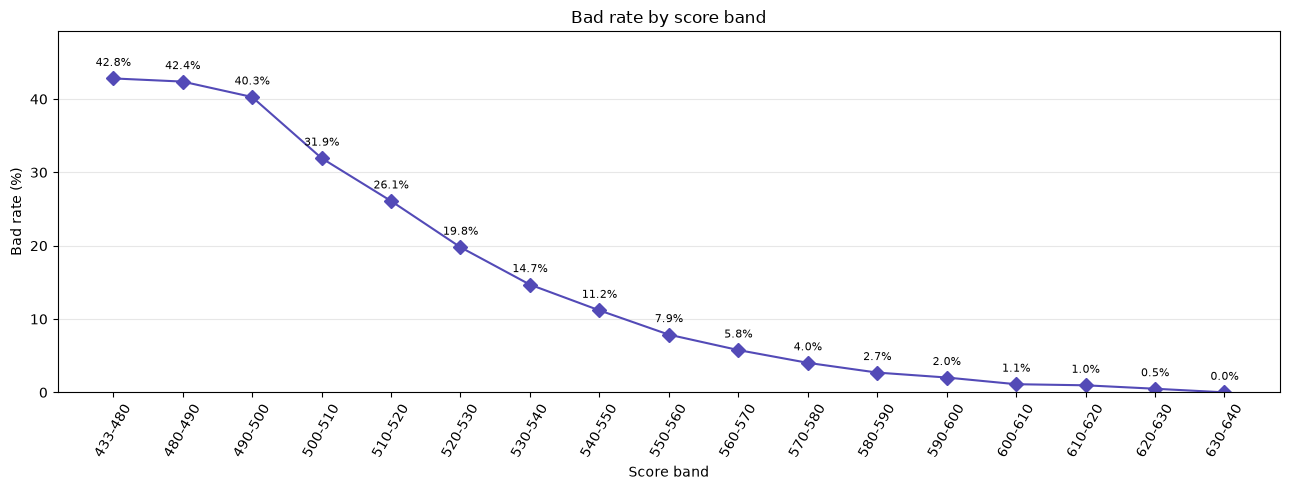

In [6]:
import numpy as np
import matplotlib.pyplot as plt

target = sc["target"]
smin, smax = test["score"].min(), test["score"].max()

# first band starts at the minimum score, then every 10 points
first = int(np.floor(smin))
edges = np.concatenate(([first], np.arange(480, int(np.ceil(smax / 10)) * 10 + 10, 10)))
if edges[-1] <= smax:
    edges = np.append(edges, edges[-1] + 10)

test["band"] = pd.cut(test["score"], bins=edges, right=False)   # [498, 510), [510, 520), ...

band = (test.groupby("band", observed=True)[target]
        .agg(bad_rate="mean", count="size")
        .reset_index())
band["label"] = band["band"].apply(lambda b: f"{int(b.left)}-{int(b.right)}")
band["bad_pct"] = band["bad_rate"] * 100

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(band["label"], band["bad_pct"], color="#534AB7", linewidth=1.5, marker="D", markersize=7)

for x, y in zip(band["label"], band["bad_pct"]):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=8)

ax.set_xlabel("Score band")
ax.set_ylabel("Bad rate (%)")
ax.set_title("Bad rate by score band")
ax.set_ylim(0, band["bad_pct"].max() * 1.15)
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
test['band'].value_counts()

band
[560, 570)    22090
[550, 560)    22082
[540, 550)    18917
[570, 580)    18111
[530, 540)    14083
[580, 590)    12166
[520, 530)     8712
[590, 600)     6823
[510, 520)     4533
[600, 610)     4053
[500, 510)     2198
[610, 620)     1458
[490, 500)     1018
[480, 490)      446
[433, 480)      292
[620, 630)      203
[630, 640)        5
Name: count, dtype: int64